## Import and data load

In [1]:
import sys
import pandas as pd
from pathlib import Path

print(sys.executable)
print(sys.version)
print(pd.__version__)

pd.set_option('display.max_columns', None)

/home/mkukreja/Desktop/Docs/BRCA/brca1-risk-prediction/.venv/bin/python
3.14.7 | packaged by conda-forge | (main, Sep  2 2026, 21:09:07) [GCC 15.3.0]
3.0.6


In [2]:
df = pd.read_csv("../data/raw/dataset.csv")
df.shape

(1600, 24)

In [3]:
df.head()

,variation_id,gene_symbol,protein_change,protein_position,ref_aa,alt_aa,clinical_significance,domain,plddt,is_stop_gained,is_frameshift,is_splice_region,label,pos_norm,distance_to_domain,plddt_at_pos,plddt_window11,hydro_delta,charge_delta,volume_delta,domain_BRCT1,domain_BRCT2,domain_OTHER,domain_RING
0,100000,BRCA1,p.C176G,176,C,G,Benign,OTHER,61.795453,0,0,0,0,0.094471,67,52.778104,57.752886,2.9,0,48.4,False,False,True,False
1,100001,BRCA1,p.F773W,773,F,W,Benign,OTHER,50.859371,0,0,0,0,0.414922,664,59.417299,49.856908,3.7,0,37.9,False,False,True,False
2,100002,BRCA1,p.R1244W,1244,R,W,Benign,OTHER,54.256865,0,0,0,0,0.667740,402,46.864676,51.135601,3.6,1,54.4,False,False,True,False
3,100003,BRCA1,p.L36C,36,L,C,Pathogenic,RING,87.909717,0,0,0,1,0.019324,0,89.439383,83.145249,1.3,0,58.2,False,False,False,True
4,100004,BRCA1,p.I1205V,1205,I,V,Likely benign,OTHER,63.506025,0,0,0,0,0.646806,441,63.869783,56.117647,0.3,0,26.7,False,False,True,False


In [4]:
df.columns.tolist()

['variation_id',
 'gene_symbol',
 'protein_change',
 'protein_position',
 'ref_aa',
 'alt_aa',
 'clinical_significance',
 'domain',
 'plddt',
 'is_stop_gained',
 'is_frameshift',
 'is_splice_region',
 'label',
 'pos_norm',
 'distance_to_domain',
 'plddt_at_pos',
 'plddt_window11',
 'hydro_delta',
 'charge_delta',
 'volume_delta',
 'domain_BRCT1',
 'domain_BRCT2',
 'domain_OTHER',
 'domain_RING']

In [5]:
df.dtypes

variation_id               int64
gene_symbol                  str
protein_change               str
protein_position           int64
ref_aa                       str
alt_aa                       str
clinical_significance        str
domain                       str
plddt                    float64
is_stop_gained             int64
is_frameshift              int64
is_splice_region           int64
label                      int64
pos_norm                 float64
distance_to_domain         int64
plddt_at_pos             float64
plddt_window11           float64
hydro_delta              float64
charge_delta               int64
volume_delta             float64
domain_BRCT1                bool
domain_BRCT2                bool
domain_OTHER                bool
domain_RING                 bool
dtype: object

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1600 entries, 0 to 1599
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   variation_id           1600 non-null   int64  
 1   gene_symbol            1600 non-null   str    
 2   protein_change         1600 non-null   str    
 3   protein_position       1600 non-null   int64  
 4   ref_aa                 1600 non-null   str    
 5   alt_aa                 1600 non-null   str    
 6   clinical_significance  1600 non-null   str    
 7   domain                 1600 non-null   str    
 8   plddt                  1600 non-null   float64
 9   is_stop_gained         1600 non-null   int64  
 10  is_frameshift          1600 non-null   int64  
 11  is_splice_region       1600 non-null   int64  
 12  label                  1600 non-null   int64  
 13  pos_norm               1600 non-null   float64
 14  distance_to_domain     1600 non-null   int64  
 15  plddt_at_pos   

## Data inspection

In [7]:
df.isnull().sum()

variation_id             0
gene_symbol              0
protein_change           0
protein_position         0
ref_aa                   0
alt_aa                   0
clinical_significance    0
domain                   0
plddt                    0
is_stop_gained           0
is_frameshift            0
is_splice_region         0
label                    0
pos_norm                 0
distance_to_domain       0
plddt_at_pos             0
plddt_window11           0
hydro_delta              0
charge_delta             0
volume_delta             0
domain_BRCT1             0
domain_BRCT2             0
domain_OTHER             0
domain_RING              0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

## categorical/value analysis

In [9]:
df["gene_symbol"].value_counts()

gene_symbol
BRCA1    1600
Name: count, dtype: int64

In [10]:
df["clinical_significance"].value_counts()

clinical_significance
Benign               559
Pathogenic           414
Likely benign        380
Likely pathogenic    247
Name: count, dtype: int64

In [11]:
df["label"].value_counts()

label
0    939
1    661
Name: count, dtype: int64

In [12]:
df["domain"].value_counts()

domain
OTHER    1337
RING       98
BRCT2      90
BRCT1      75
Name: count, dtype: int64

## Summary

In [13]:
df.describe()

,variation_id,protein_position,plddt,is_stop_gained,is_frameshift,is_splice_region,label,pos_norm,distance_to_domain,plddt_at_pos,plddt_window11,hydro_delta,charge_delta,volume_delta
count,1600.00000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000
mean,100799.50000,935.031875,57.626156,0.089375,0.101250,0.056250,0.413125,0.501896,307.230000,57.646664,57.518809,3.505313,0.476875,48.389312
std,462.02453,544.868609,15.257829,0.285373,0.301754,0.230476,0.492549,0.292468,244.411551,14.780929,13.564090,2.446875,0.568698,33.372782
min,100000.00000,1.000000,26.585780,0.000000,0.000000,0.000000,0.000000,0.000537,0.000000,27.900595,39.872967,0.000000,0.000000,0.000000
25%,100399.75000,443.750000,47.128614,0.000000,0.000000,0.000000,0.000000,0.238191,60.750000,47.582690,47.365507,1.400000,0.000000,23.900000
50%,100799.50000,955.500000,54.511761,0.000000,0.000000,0.000000,0.000000,0.512882,283.500000,53.973868,54.571564,3.000000,0.000000,49.400000
75%,101199.25000,1400.250000,63.506068,0.000000,0.000000,0.000000,1.000000,0.751610,517.000000,62.878395,59.915689,5.400000,1.000000,64.900000
max,101599.00000,1861.000000,98.000000,1.000000,1.000000,1.000000,1.000000,0.998926,767.000000,98.000000,93.290833,9.000000,2.000000,167.700000


In [14]:
# How many distinct values does each column contain?
df.nunique()

variation_id             1600
gene_symbol                 1
protein_change           1599
protein_position         1088
ref_aa                     20
alt_aa                     20
clinical_significance       4
domain                      4
plddt                    1585
is_stop_gained              2
is_frameshift               2
is_splice_region            2
label                       2
pos_norm                 1088
distance_to_domain        636
plddt_at_pos             1081
plddt_window11           1088
hydro_delta                84
charge_delta                3
volume_delta              168
domain_BRCT1                2
domain_BRCT2                2
domain_OTHER                2
domain_RING                 2
dtype: int64

In [15]:
# Which rows share the same protein change?
df[df["protein_change"].duplicated(keep=False)]

,variation_id,gene_symbol,protein_change,protein_position,ref_aa,alt_aa,clinical_significance,domain,plddt,is_stop_gained,is_frameshift,is_splice_region,label,pos_norm,distance_to_domain,plddt_at_pos,plddt_window11,hydro_delta,charge_delta,volume_delta,domain_BRCT1,domain_BRCT2,domain_OTHER,domain_RING
63,100063,BRCA1,p.S1191A,1191,S,A,Likely benign,OTHER,64.227355,0,0,0,0,0.639291,455,53.114076,55.983278,2.6,0,0.4,False,False,True,False
232,100232,BRCA1,p.S1191A,1191,S,A,Benign,OTHER,64.363177,0,0,0,0,0.639291,455,53.114076,55.983278,2.6,0,0.4,False,False,True,False


## Clinical annotation cross-tabs

In [16]:
# What percentage of rows has each clinical annotation?
df["clinical_significance"].value_counts(normalize=True).mul(100).round(2)

clinical_significance
Benign               34.94
Pathogenic           25.87
Likely benign        23.75
Likely pathogenic    15.44
Name: proportion, dtype: float64

In [17]:
# How do the clinical annotations correspond to the supplied labels?
pd.crosstab(df["clinical_significance"], df["label"])

label,0,1
clinical_significance,,
Benign,559,0
Likely benign,380,0
Likely pathogenic,0,247
Pathogenic,0,414


In [18]:
# How many rows of each clinical annotation occur in each domain?
pd.crosstab(df["domain"], df["clinical_significance"])

clinical_significance,Benign,Likely benign,Likely pathogenic,Pathogenic
domain,,,,
BRCT1,14,7,19,35
BRCT2,14,18,25,33
OTHER,524,345,168,300
RING,7,10,35,46


In [19]:
# Within each domain, what percentage of rows has each clinical annotation?
pd.crosstab(df["domain"], df["clinical_significance"], normalize="index").mul(100).round(2)

clinical_significance,Benign,Likely benign,Likely pathogenic,Pathogenic
domain,,,,
BRCT1,18.67,9.33,25.33,46.67
BRCT2,15.56,20.00,27.78,36.67
OTHER,39.19,25.80,12.57,22.44
RING,7.14,10.20,35.71,46.94


In [20]:
# How are stop-gained annotations distributed across clinical annotations?
pd.crosstab(df["is_stop_gained"], df["clinical_significance"])

clinical_significance,Benign,Likely benign,Likely pathogenic,Pathogenic
is_stop_gained,,,,
0,545,372,200,340
1,14,8,47,74


In [21]:
# How are frameshift annotations distributed across clinical annotations?
pd.crosstab(df["is_frameshift"], df["clinical_significance"])

clinical_significance,Benign,Likely benign,Likely pathogenic,Pathogenic
is_frameshift,,,,
0,535,369,201,333
1,24,11,46,81


In [22]:
# How are splice-region annotations distributed across clinical annotations?
pd.crosstab(df["is_splice_region"], df["clinical_significance"])

clinical_significance,Benign,Likely benign,Likely pathogenic,Pathogenic
is_splice_region,,,,
0,551,373,219,367
1,8,7,28,47


## Numerical values by clinical annotation

In [23]:
# How does the supplied pLDDT distribution vary across clinical annotations?
df.groupby("clinical_significance")["plddt"].describe()

,count,mean,std,min,25%,50%,75%,max
clinical_significance,,,,,,,,
Benign,559.0,54.301632,11.852860,26.585780,47.036702,53.096044,59.619952,98.000000
Likely benign,380.0,54.590679,12.830910,32.591161,45.564835,52.359255,60.338343,95.966793
Likely pathogenic,247.0,63.038042,17.958719,30.386022,49.040014,58.254783,80.002838,98.000000
Pathogenic,414.0,61.672421,17.634247,32.050457,48.134277,55.670852,78.027986,98.000000


In [24]:
# What are the median supplied substitution deltas in each annotation group?
df.groupby("clinical_significance")[["hydro_delta", "charge_delta", "volume_delta"]].median()

,hydro_delta,charge_delta,volume_delta
clinical_significance,,,
Benign,2.8,0.0,39.10
Likely benign,2.8,0.0,40.45
Likely pathogenic,3.2,0.0,53.60
Pathogenic,3.4,0.0,51.00


## Basic plots

In [25]:
import matplotlib.pyplot as plt

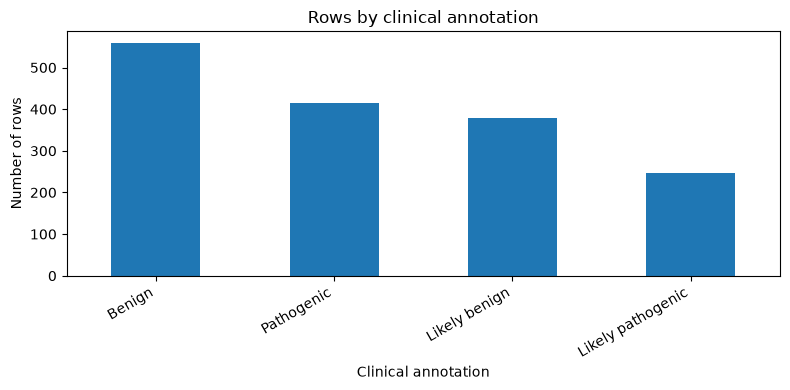

In [26]:
# How many rows belong to each clinical annotation?
df["clinical_significance"].value_counts().plot.bar(figsize=(8, 4))
plt.title("Rows by clinical annotation")
plt.xlabel("Clinical annotation")
plt.ylabel("Number of rows")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

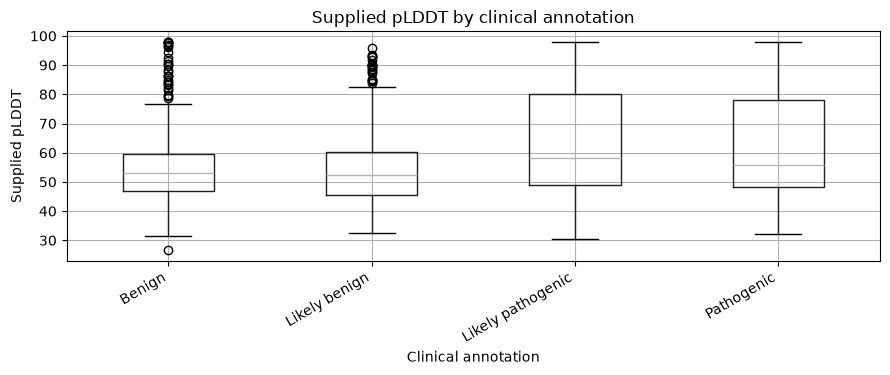

In [27]:
# How is supplied pLDDT distributed within each clinical annotation?
df.boxplot(column="plddt", by="clinical_significance", figsize=(9, 4))
plt.title("Supplied pLDDT by clinical annotation")
plt.suptitle("")
plt.xlabel("Clinical annotation")
plt.ylabel("Supplied pLDDT")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()